In [51]:
import matplotlib.pyplot as plt
import numpy as np

In [52]:
%cd Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/plots/

/home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/plots


In [53]:
abc_list = np.array([
      (3955/1024, -8306/1024, 5008/1024),
      (3735/1024, -6681/1024, 3463/1024),
      (3799/1024, -6499/1024, 3211/1024),
      (4019/1024, -6385/1024, 2906/1024),
      (2677/1024, -3029/1024, 1162/1024),
      (2172/1024, -1833/1024,  682/1024)
   ])

# cesista code
"""obtained by running the skript of
@misc{cesista2025muonoptcoeffs,
  author = {Franz Louis Cesista and You Jiacheng and Keller Jordan},
  title = {{S}queezing 1-2% Efficiency Gains Out of {M}uon by Optimizing the {N}ewton-{S}chulz {C}oefficients},
  year = {2025},
  month = {February},
  day = {21},
  url = {https://leloykun.github.io/ponder/muon-opt-coeffs/},
}

with 200000 steps, for 6 polyonomial-iterations.
Code was modified by me using 
-learning rate decay for Adam
-samples: jnp.linspace(0, 1.1, 2**13), jnp.linspace(0, 0.1, 2**12)
"""
abc_cesista = np.array([
   (3.9947, -8.6494, 4.7603),
   (3.9943, -8.6482, 4.7597),
   (3.9702, -8.5041, 4.6666),
   (3.6505, -7.0837, 3.7913),
   (2.6632, -3.9414, 2.0658),
   (2.2803, -2.2275, 0.9689),
])
abc_keller = np.array([[3.4445, -4.7750, 2.0315]])
abc_keller_iterated = abc_keller * np.ones((6, 1))

In [54]:

def apply_polynom(coeffs, inp):
    # maybe the order is the wrong way around
    return coeffs[0] * inp + coeffs[1] * (inp ** 3) + coeffs[2] * (inp ** 5)

def iterate_apply_polynom(coeffs_list, inp):
    for coeffs in coeffs_list:
        inp = apply_polynom(coeffs, inp)
    return inp

In [55]:
n_samples = 10_000
left = -0.1
right = 1.05
x = np.linspace(left, right, n_samples)


y_you_jiacheng = iterate_apply_polynom(abc_list, x)
y_abc_cesista = iterate_apply_polynom(abc_cesista, x)
y_abc_keller = iterate_apply_polynom(abc_keller, x)
y_keller_iterated = iterate_apply_polynom(abc_keller_iterated, x)

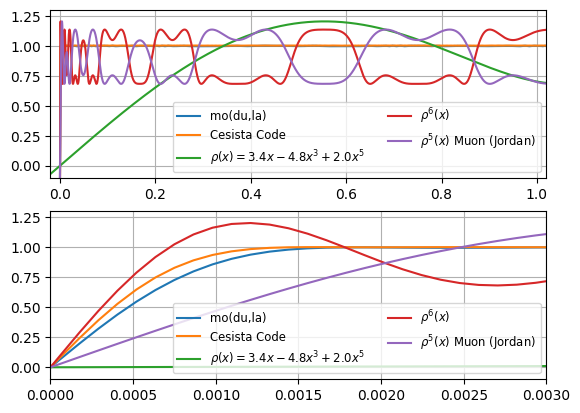

In [56]:
fig, axs = plt.subplots(nrows=2)
axs[0].set_ylim(bottom=-0.1, top=1.3)
axs[0].set_xlim(left=-0.02, right=1.02)
axs[0].grid(True)

axs[0].plot(x, y_you_jiacheng, label="mo(du,la)")
axs[0].plot(x, y_abc_cesista, label="Cesista Code")
axs[0].plot(x, y_abc_keller, label=r"$\rho(x)=3.4x-4.8x^3+2.0x^5$")
axs[0].plot(x, y_keller_iterated, label=r"$\rho^6(x)$")
axs[0].plot(x, iterate_apply_polynom(abc_keller_iterated[:-1], x), label=r"$\rho^5(x)$ Muon (Jordan)")
axs[0].legend(loc="lower right", ncol=2, fontsize="small")

axs[1].grid(True)
axs[1].set_ylim(bottom=-0.1, top=1.3)
axs[1].set_xlim(left=0, right=0.003)
axs[1].plot(x, y_you_jiacheng, label="mo(du,la)")
axs[1].plot(x, y_abc_cesista, label="Cesista Code")
axs[1].plot(x, y_abc_keller, label=r"$\rho(x)=3.4x-4.8x^3+2.0x^5$")
axs[1].plot(x, y_keller_iterated, label=r"$\rho^6(x)$")
axs[1].plot(x, iterate_apply_polynom(abc_keller_iterated[:-1], x), label=r"$\rho^5(x)$ Muon (Jordan)")
axs[1].legend(loc="lower right", ncol=2, fontsize="small")


plt.savefig("polynom_comparison_plots.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()

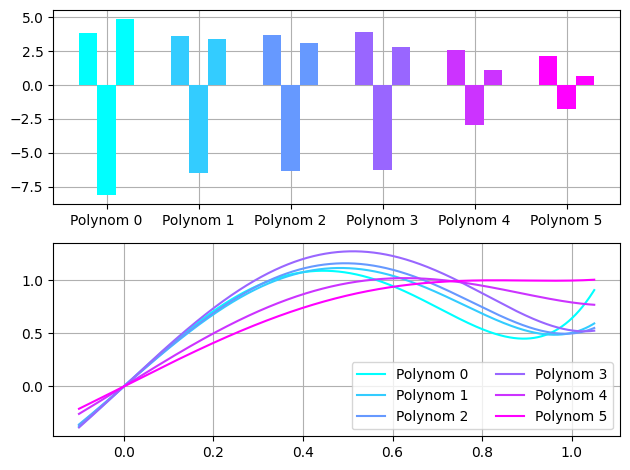

In [57]:
fig, axs = plt.subplots(nrows=2)
breadth = 0.2
rows = np.arange(6)
colormap = plt.colormaps['cool']

for i in range(6):
    color_i = i / 5
    color = colormap(color_i)
    
    axs[0].bar(i - breadth, abc_list[i, 0], breadth, color=color)
    axs[0].bar(i,           abc_list[i, 1], breadth, color=color)
    axs[0].bar(i + breadth, abc_list[i, 2], breadth, color=color)

axs[0].grid(True)
axs[0].set_axisbelow(True)
axs[0].set_xticks(rows)
axs[0].set_xticklabels([f"Polynom {i}" for i in rows])

for i in range(6):
    color_i = i / 5
    color = colormap(color_i)
    axs[1].plot(x, apply_polynom(abc_list[i], x), color=color, label=f"Polynom {i}")

axs[1].grid(True)
axs[1].legend(ncol=2)
plt.tight_layout() 

plt.savefig("iterations_optimierte_polynome_modula.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()


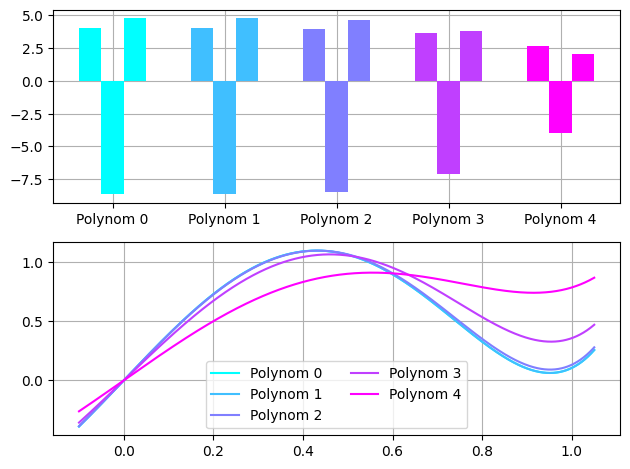

In [58]:
n_iter=5

fig, axs = plt.subplots(nrows=2)
breadth = 0.2
rows = np.arange(n_iter)
colormap = plt.colormaps['cool']

for i in range(n_iter):
    color_i = i / (n_iter-1)
    color = colormap(color_i)
    
    axs[0].bar(i - breadth, abc_cesista[i, 0], breadth, color=color)
    axs[0].bar(i,           abc_cesista[i, 1], breadth, color=color)
    axs[0].bar(i + breadth, abc_cesista[i, 2], breadth, color=color)

axs[0].grid(True)
axs[0].set_axisbelow(True)
axs[0].set_xticks(rows)
axs[0].set_xticklabels([f"Polynom {i}" for i in rows])

for i in range(n_iter):
    color_i = i / (n_iter-1)
    color = colormap(color_i)
    axs[1].plot(x, apply_polynom(abc_cesista[i], x), color=color, label=f"Polynom {i}")

axs[1].grid(True)
axs[1].legend(ncol=2)
plt.tight_layout() 

plt.savefig("iterations_optimierte_polynome_cesista.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()